# Decoder Complexity Analysis

This notebook investigates which structural and noise properties of a surface-code decoding problem drive classical processing cost.

### Swept Parameters
The benchmark systematically varies:
* Rotated surface-code distance ($d$);
* Circuit-level physical error probability ($p$);
* Number of syndrome-extraction rounds;
* Detector-graph scale (number of detectors and edges);
* Detection-event count and density per shot;
* Decoder batch size.

### Principal Questions
1. How does PyMatching runtime scale with rotated surface-code distance?
2. Does higher physical noise significantly increase classical decoding cost?
3. How strongly is detection-event count associated with single-shot decoding latency?
4. Do logical decoding failures correspond to unusually dense detector syndromes?
5. How effectively does batching amortise invocation overhead to reduce effective per-shot latency?

### Scope and Measurement Caveat
Because wall-clock timings capture Python-binding overhead, operating-system scheduling, and host CPU architecture effects, these measurements characterise the empirical behaviour of the current software stack rather than the theoretical, hardware-independent asymptotic complexity of minimum-weight perfect matching (MWPM).



In [1]:
# Imports and project paths
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymatching
import stim

PROJECT_DIR = Path(
    r"C:\Users\Karthi\Qauntum"
).resolve()

FIGURE_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

SEED = 42

print(f"Project directory: {PROJECT_DIR}")
print("Decoder complexity environment ready.")

Project directory: C:\Users\Karthi\Qauntum
Decoder complexity environment ready.


In [2]:
# One decoder workload
# Generate a rotated surface-code memory circuit, decoder and detector samples

# Syndrome rounds are set equal to code distance
def prepare_surface_code_workload(
    distance,
    physical_error_probability,
    number_of_shots,
    seed=SEED,
):

    if distance < 3 or distance % 2 == 0:
        raise ValueError(
            "distance must be an odd integer greater than or equal to 3."
        )

    if not (
        0.0
        <= physical_error_probability
        <= 1.0
    ):
        raise ValueError(
            "physical_error_probability must be between zero and one."
        )

    if number_of_shots <= 0:
        raise ValueError(
            "number_of_shots must be positive."
        )

    rounds = distance

    circuit = stim.Circuit.generated(
        "surface_code:rotated_memory_x",
        distance=distance,
        rounds=rounds,
        after_clifford_depolarization=(
            physical_error_probability
        ),
        before_round_data_depolarization=(
            physical_error_probability
        ),
        before_measure_flip_probability=(
            physical_error_probability
        ),
        after_reset_flip_probability=(
            physical_error_probability
        ),
    )

    detector_error_model = (
        circuit.detector_error_model(
            decompose_errors=True
        )
    )

    decoder = (
        pymatching.Matching
        .from_detector_error_model(
            detector_error_model
        )
    )

    sampler = (
        circuit.compile_detector_sampler(
            seed=seed
        )
    )

    detection_events, actual_observables = (
        sampler.sample(
            shots=number_of_shots,
            separate_observables=True,
        )
    )

    return {
        "distance": distance,
        "rounds": rounds,
        "physical_error_probability": (
            physical_error_probability
        ),
        "circuit": circuit,
        "detector_error_model": (
            detector_error_model
        ),
        "decoder": decoder,
        "detection_events": (
            detection_events
        ),
        "actual_observables": (
            actual_observables
        ),
    }

In [3]:
# Benchmark workload
# Measure batch throughput and sampled individual decoding latency for one surface-code workload
def benchmark_surface_code_workload(
    distance,
    physical_error_probability,
    number_of_shots=20_000,
    individual_timing_shots=1_000,
    batch_timing_repeats=5,
    seed=SEED,
):


    workload = prepare_surface_code_workload(
        distance=distance,
        physical_error_probability=(
            physical_error_probability
        ),
        number_of_shots=number_of_shots,
        seed=seed,
    )

    circuit = workload["circuit"]
    decoder = workload["decoder"]
    detection_events = workload[
        "detection_events"
    ]
    actual_observables = workload[
        "actual_observables"
    ]

    detector_counts = detection_events.sum(
        axis=1
    )

    # Warm up the decoder.
    decoder.decode_batch(
        detection_events[:10]
    )

    batch_times = []

    for _ in range(
        batch_timing_repeats
    ):
        start_time = perf_counter()

        predicted_observables = (
            decoder.decode_batch(
                detection_events
            )
        )

        end_time = perf_counter()

        batch_times.append(
            end_time - start_time
        )

    batch_times = np.asarray(
        batch_times,
        dtype=float,
    )

    median_batch_time = float(
        np.median(
            batch_times
        )
    )

    decoding_failures = np.any(
        predicted_observables
        != actual_observables,
        axis=1,
    )

    logical_failure_count = int(
        decoding_failures.sum()
    )

    selected_shot_count = min(
        individual_timing_shots,
        number_of_shots,
    )

    # Sample throughout the dataset instead of using
    # only the first consecutive block.
    selected_indices = np.linspace(
        0,
        number_of_shots - 1,
        selected_shot_count,
        dtype=int,
    )

    individual_results = []

    # Warm up individual decode calls.
    for sample_index in selected_indices[:50]:
        decoder.decode(
            detection_events[
                sample_index
            ]
        )

    for sample_index in selected_indices:
        detector_sample = detection_events[
            sample_index
        ]

        start_time = perf_counter()

        decoder.decode(
            detector_sample
        )

        end_time = perf_counter()

        latency_microseconds = (
            1e6
            * (
                end_time - start_time
            )
        )

        individual_results.append(
            {
                "distance": distance,
                "rounds": distance,
                "physical_error_probability": (
                    physical_error_probability
                ),
                "shot_index": int(
                    sample_index
                ),
                "detection_events": int(
                    detector_counts[
                        sample_index
                    ]
                ),
                "detector_density": float(
                    detector_counts[
                        sample_index
                    ]
                    / circuit.num_detectors
                ),
                "latency_microseconds": (
                    latency_microseconds
                ),
                "logical_failure": bool(
                    decoding_failures[
                        sample_index
                    ]
                ),
            }
        )

    individual_df = pd.DataFrame(
        individual_results
    )

    summary = {
        "distance": distance,
        "rounds": distance,
        "physical_error_probability": (
            physical_error_probability
        ),
        "shots": number_of_shots,
        "qubits": circuit.num_qubits,
        "measurements": (
            circuit.num_measurements
        ),
        "detectors": (
            circuit.num_detectors
        ),
        "matching_edges": (
            decoder.num_edges
        ),
        "logical_failures": (
            logical_failure_count
        ),
        "logical_failure_probability": (
            logical_failure_count
            / number_of_shots
        ),
        "mean_detection_events": float(
            detector_counts.mean()
        ),
        "median_detection_events": float(
            np.median(
                detector_counts
            )
        ),
        "p95_detection_events": float(
            np.percentile(
                detector_counts,
                95,
            )
        ),
        "mean_detector_density": float(
            detector_counts.mean()
            / circuit.num_detectors
        ),
        "median_batch_seconds": (
            median_batch_time
        ),
        "batch_microseconds_per_shot": (
            1e6
            * median_batch_time
            / number_of_shots
        ),
        "batch_shots_per_second": (
            number_of_shots
            / median_batch_time
        ),
        "individual_samples": (
            len(
                individual_df
            )
        ),
        "individual_mean_microseconds": float(
            individual_df[
                "latency_microseconds"
            ].mean()
        ),
        "individual_median_microseconds": float(
            individual_df[
                "latency_microseconds"
            ].median()
        ),
        "individual_p95_microseconds": float(
            individual_df[
                "latency_microseconds"
            ].quantile(
                0.95
            )
        ),
        "individual_p99_microseconds": float(
            individual_df[
                "latency_microseconds"
            ].quantile(
                0.99
            )
        ),
    }

    return summary, individual_df

In [4]:
# Test function
test_summary, test_individual_df = (
    benchmark_surface_code_workload(
        distance=3,
        physical_error_probability=0.005,
        number_of_shots=5_000,
        individual_timing_shots=500,
        batch_timing_repeats=3,
        seed=SEED,
    )
)

pd.Series(
    test_summary
)

distance                          3.000000e+00
rounds                            3.000000e+00
physical_error_probability        5.000000e-03
shots                             5.000000e+03
qubits                            2.600000e+01
measurements                      3.300000e+01
detectors                         2.400000e+01
matching_edges                    7.800000e+01
logical_failures                  8.700000e+01
logical_failure_probability       1.740000e-02
mean_detection_events             1.462800e+00
median_detection_events           1.000000e+00
p95_detection_events              5.000000e+00
mean_detector_density             6.095000e-02
median_batch_seconds              1.212600e-03
batch_microseconds_per_shot       2.425200e-01
batch_shots_per_second            4.123372e+06
individual_samples                5.000000e+02
individual_mean_microseconds      3.176000e+00
individual_median_microseconds    3.100024e+00
individual_p95_microseconds       3.905024e+00
individual_p9

In [5]:
# Validation
assert test_summary["distance"] == 3

assert (
    test_summary[
        "batch_microseconds_per_shot"
    ] > 0.0
)

assert (
    test_individual_df[
        "latency_microseconds"
    ] > 0.0
).all()

print(
    "Decoder benchmark function passed "
    "its initial test."
)

Decoder benchmark function passed its initial test.


In [6]:
# Constants
DISTANCES = [
    3,
    5,
    7,
    9,
]

PHYSICAL_ERROR_PROBABILITIES = [
    0.003,
    0.007,
    0.012,
]

SHOTS_PER_CONFIGURATION = 20_000
INDIVIDUAL_TIMING_SHOTS = 1_000
BATCH_TIMING_REPEATS = 5

In [7]:
# Run the sweep
complexity_summaries = []
individual_latency_tables = []

configuration_index = 0
total_configurations = (
    len(DISTANCES)
    * len(
        PHYSICAL_ERROR_PROBABILITIES
    )
)

for distance in DISTANCES:
    for physical_probability in (
        PHYSICAL_ERROR_PROBABILITIES
    ):
        configuration_index += 1

        print(
            f"Running "
            f"{configuration_index}/"
            f"{total_configurations} | "
            f"distance={distance} | "
            f"p={physical_probability:.3%}"
        )

        summary, individual_df = (
            benchmark_surface_code_workload(
                distance=distance,
                physical_error_probability=(
                    physical_probability
                ),
                number_of_shots=(
                    SHOTS_PER_CONFIGURATION
                ),
                individual_timing_shots=(
                    INDIVIDUAL_TIMING_SHOTS
                ),
                batch_timing_repeats=(
                    BATCH_TIMING_REPEATS
                ),
                seed=(
                    SEED
                    + configuration_index
                ),
            )
        )

        complexity_summaries.append(
            summary
        )

        individual_latency_tables.append(
            individual_df
        )

        print(
            f"  batch="
            f"{summary['batch_microseconds_per_shot']:.4f} "
            f"us/shot | "
            f"single median="
            f"{summary['individual_median_microseconds']:.4f} "
            f"us | "
            f"events="
            f"{summary['mean_detection_events']:.2f}"
        )

Running 1/12 | distance=3 | p=0.300%
  batch=0.1427 us/shot | single median=2.9000 us | events=0.90
Running 2/12 | distance=3 | p=0.700%
  batch=0.3411 us/shot | single median=3.2000 us | events=1.98
Running 3/12 | distance=3 | p=1.200%
  batch=0.5616 us/shot | single median=3.3000 us | events=3.16
Running 4/12 | distance=5 | p=0.300%
  batch=1.0297 us/shot | single median=3.9000 us | events=5.24
Running 5/12 | distance=5 | p=0.700%
  batch=2.9451 us/shot | single median=5.6000 us | events=11.48
Running 6/12 | distance=5 | p=1.200%
  batch=5.6070 us/shot | single median=7.9001 us | events=18.29
Running 7/12 | distance=7 | p=0.300%
  batch=3.1666 us/shot | single median=6.1000 us | events=15.70
Running 8/12 | distance=7 | p=0.700%
  batch=10.0667 us/shot | single median=12.4000 us | events=34.26
Running 9/12 | distance=7 | p=1.200%
  batch=20.8194 us/shot | single median=23.2001 us | events=54.37
Running 10/12 | distance=9 | p=0.300%
  batch=7.3544 us/shot | single median=10.9000 us | e

In [8]:
# Combine data
complexity_summary_df = pd.DataFrame(
    complexity_summaries
)

individual_latency_df = pd.concat(
    individual_latency_tables,
    ignore_index=True,
)

complexity_summary_df

,distance,rounds,physical_error_probability,shots,qubits,measurements,detectors,matching_edges,logical_failures,logical_failure_probability,...,p95_detection_events,mean_detector_density,median_batch_seconds,batch_microseconds_per_shot,batch_shots_per_second,individual_samples,individual_mean_microseconds,individual_median_microseconds,individual_p95_microseconds,individual_p99_microseconds
0,3,3,0.003,20000,26,33,24,78,152,0.00760,...,4.0,0.037344,0.002855,0.142730,7.006235e+06,1000,3.215301,2.900022,3.700028,4.702921
1,3,3,0.007,20000,26,33,24,78,712,0.03560,...,6.0,0.082388,0.006822,0.341115,2.931563e+06,1000,3.293700,3.200024,4.100031,5.401041
2,3,3,0.012,20000,26,33,24,78,1773,0.08865,...,7.0,0.131527,0.011232,0.561590,1.780658e+06,1000,3.550400,3.300025,4.899927,6.702050
3,5,5,0.003,20000,64,145,120,502,86,0.00430,...,11.0,0.043702,0.020594,1.029685,9.711708e+05,1000,4.194699,3.900030,6.099936,9.200955
4,5,5,0.007,20000,64,145,120,502,875,0.04375,...,20.0,0.095704,0.058902,2.945100,3.395470e+05,1000,6.244901,5.599984,10.299968,13.601987
5,5,5,0.012,20000,64,145,120,502,2872,0.14360,...,28.0,0.152390,0.112140,5.607025,1.783477e+05,1000,8.564901,7.900060,14.709996,18.202906
6,7,7,0.003,20000,118,385,336,1558,33,0.00165,...,26.0,0.046741,0.063332,3.166590,3.157971e+05,1000,6.597201,6.100046,10.305073,14.500994
7,7,7,0.007,20000,118,385,336,1558,843,0.04215,...,49.0,0.101965,0.201334,10.066690,9.933752e+04,1000,13.689101,12.399978,23.800065,34.409028
8,7,7,0.012,20000,118,385,336,1558,3984,0.19920,...,71.0,0.161814,0.416387,20.819355,4.803223e+04,1000,24.517400,23.200060,39.615063,51.402042
9,9,9,0.003,20000,188,801,720,3534,14,0.00070,...,51.0,0.048586,0.147089,7.354440,1.359723e+05,1000,11.951402,10.900025,19.405031,28.212982


In [9]:
# Graph and workload scaling
graph_scaling_df = (
    complexity_summary_df[
        [
            "distance",
            "qubits",
            "measurements",
            "detectors",
            "matching_edges",
        ]
    ]
    .drop_duplicates(
        subset=["distance"]
    )
    .sort_values(
        "distance"
    )
)

graph_scaling_df

,distance,qubits,measurements,detectors,matching_edges
0,3,26,33,24,78
3,5,64,145,120,502
6,7,118,385,336,1558
9,9,188,801,720,3534


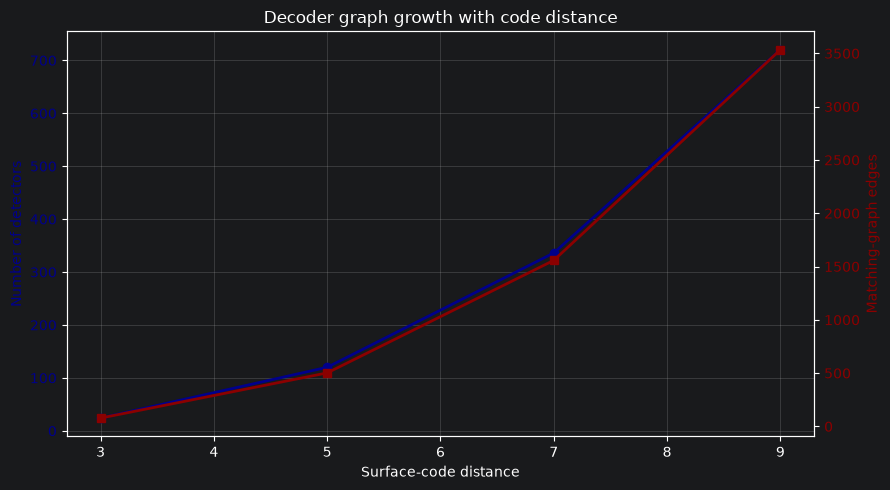

In [10]:
# Plot detectors and matching edges
figure, primary_axis = plt.subplots(
    figsize=(9, 5)
)

primary_axis.plot(
    graph_scaling_df["distance"],
    graph_scaling_df["detectors"],
    marker="o",
    linewidth=2,
    color="darkblue",
    label="Detectors",
)

primary_axis.set_xlabel(
    "Surface-code distance"
)

primary_axis.set_ylabel(
    "Number of detectors",
    color="darkblue",
)

primary_axis.tick_params(
    axis="y",
    labelcolor="darkblue",
)

secondary_axis = (
    primary_axis.twinx()
)

secondary_axis.plot(
    graph_scaling_df["distance"],
    graph_scaling_df["matching_edges"],
    marker="s",
    linewidth=2,
    color="darkred",
    label="Matching edges",
)

secondary_axis.set_ylabel(
    "Matching-graph edges",
    color="darkred",
)

secondary_axis.tick_params(
    axis="y",
    labelcolor="darkred",
)

primary_axis.set_title(
    "Decoder graph growth with code distance"
)

primary_axis.grid(
    True,
    alpha=0.3,
)

figure.tight_layout()

graph_growth_path = (
    FIGURE_DIR
    / "decoder_graph_complexity.png"
)

figure.savefig(
    graph_growth_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

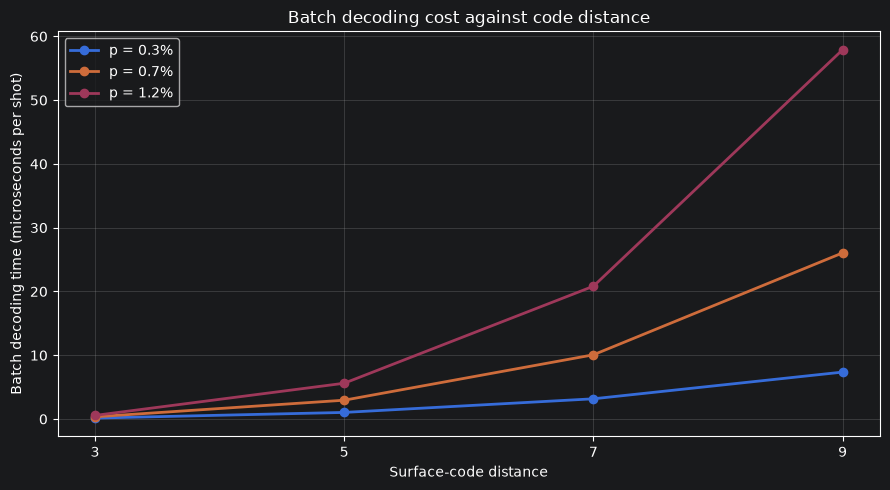

In [11]:
# Plot batch cost against distance
figure, axis = plt.subplots(
    figsize=(9, 5)
)

for physical_probability in (
    PHYSICAL_ERROR_PROBABILITIES
):
    subset = complexity_summary_df[
        np.isclose(
            complexity_summary_df[
                "physical_error_probability"
            ],
            physical_probability,
        )
    ].sort_values(
        "distance"
    )

    axis.plot(
        subset["distance"],
        subset[
            "batch_microseconds_per_shot"
        ],
        marker="o",
        linewidth=2,
        label=(
            f"p = "
            f"{physical_probability:.1%}"
        ),
    )

axis.set_xlabel(
    "Surface-code distance"
)

axis.set_ylabel(
    "Batch decoding time "
    "(microseconds per shot)"
)

axis.set_title(
    "Batch decoding cost against code distance"
)

axis.set_xticks(
    DISTANCES
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

batch_distance_path = (
    FIGURE_DIR
    / "decoder_batch_cost_by_distance.png"
)

figure.savefig(
    batch_distance_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

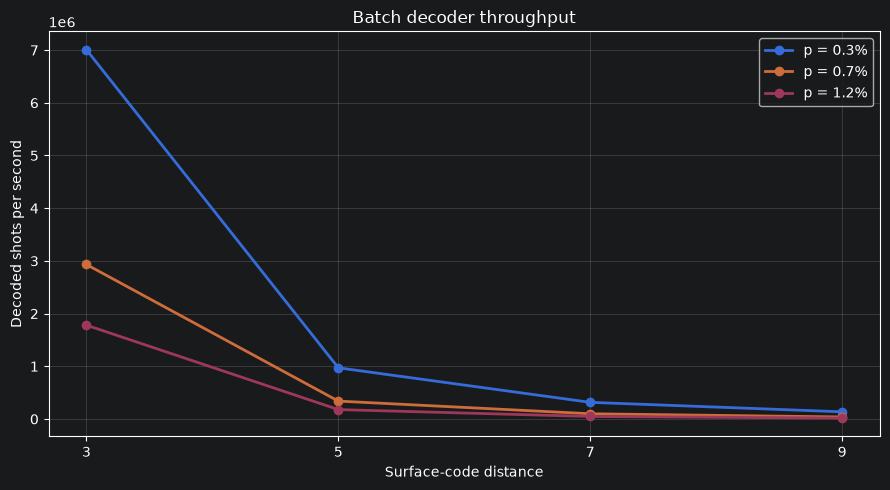

In [12]:
# Plot throughput
figure, axis = plt.subplots(
    figsize=(9, 5)
)

for physical_probability in (
    PHYSICAL_ERROR_PROBABILITIES
):
    subset = complexity_summary_df[
        np.isclose(
            complexity_summary_df[
                "physical_error_probability"
            ],
            physical_probability,
        )
    ].sort_values(
        "distance"
    )

    axis.plot(
        subset["distance"],
        subset[
            "batch_shots_per_second"
        ],
        marker="o",
        linewidth=2,
        label=(
            f"p = "
            f"{physical_probability:.1%}"
        ),
    )

axis.set_xlabel(
    "Surface-code distance"
)

axis.set_ylabel(
    "Decoded shots per second"
)

axis.set_title(
    "Batch decoder throughput"
)

axis.set_xticks(
    DISTANCES
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

throughput_path = (
    FIGURE_DIR
    / "decoder_throughput_by_distance.png"
)

figure.savefig(
    throughput_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [13]:
# Calculate correlations by configuration
correlation_results = []

for (
    distance,
    physical_probability
), group in individual_latency_df.groupby(
    [
        "distance",
        "physical_error_probability",
    ]
):
    pearson = group[
        [
            "detection_events",
            "latency_microseconds",
        ]
    ].corr(
        method="pearson"
    ).iloc[0, 1]

    spearman = group[
        [
            "detection_events",
            "latency_microseconds",
        ]
    ].corr(
        method="spearman"
    ).iloc[0, 1]

    density_spearman = group[
        [
            "detector_density",
            "latency_microseconds",
        ]
    ].corr(
        method="spearman"
    ).iloc[0, 1]

    correlation_results.append(
        {
            "distance": distance,
            "physical_error_probability": (
                physical_probability
            ),
            "samples": len(group),
            "pearson_event_latency": (
                pearson
            ),
            "spearman_event_latency": (
                spearman
            ),
            "spearman_density_latency": (
                density_spearman
            ),
        }
    )

correlation_df = pd.DataFrame(
    correlation_results
)

correlation_df

,distance,physical_error_probability,samples,pearson_event_latency,spearman_event_latency,spearman_density_latency
0,3,0.003,1000,0.066986,0.831943,0.831943
1,3,0.007,1000,0.677088,0.890257,0.890257
2,3,0.012,1000,0.696126,0.898795,0.898795
3,5,0.003,1000,0.562932,0.898730,0.898730
4,5,0.007,1000,0.453008,0.775345,0.775345
5,5,0.012,1000,0.725004,0.742222,0.742222
6,7,0.003,1000,0.693441,0.838023,0.838023
7,7,0.007,1000,0.669557,0.754769,0.754769
8,7,0.012,1000,0.602437,0.649057,0.649057
9,9,0.003,1000,0.647600,0.794139,0.794139


In [14]:
# Plot latency against detection-event count
distance_nine_df = (
    individual_latency_df[
        individual_latency_df[
            "distance"
        ] == 9
    ]
)

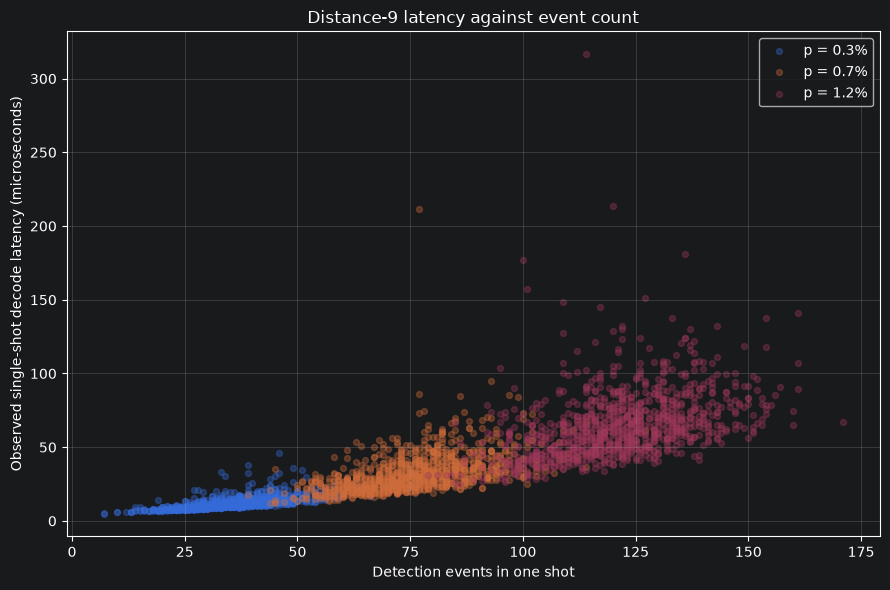

In [15]:
# Plot
figure, axis = plt.subplots(
    figsize=(9, 6)
)

for physical_probability in (
    PHYSICAL_ERROR_PROBABILITIES
):
    subset = distance_nine_df[
        np.isclose(
            distance_nine_df[
                "physical_error_probability"
            ],
            physical_probability,
        )
    ]

    axis.scatter(
        subset[
            "detection_events"
        ],
        subset[
            "latency_microseconds"
        ],
        s=18,
        alpha=0.35,
        label=(
            f"p = "
            f"{physical_probability:.1%}"
        ),
    )

axis.set_xlabel(
    "Detection events in one shot"
)

axis.set_ylabel(
    "Observed single-shot decode latency "
    "(microseconds)"
)

axis.set_title(
    "Distance-9 latency against event count"
)

axis.grid(
    True,
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

latency_scatter_path = (
    FIGURE_DIR
    / "decoder_latency_event_scatter.png"
)

figure.savefig(
    latency_scatter_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [16]:
# Compare event counts
failure_complexity_results = []

for (
    distance,
    physical_probability
), group in individual_latency_df.groupby(
    [
        "distance",
        "physical_error_probability",
    ]
):
    successful_group = group[
        ~group["logical_failure"]
    ]

    failed_group = group[
        group["logical_failure"]
    ]

    failure_complexity_results.append(
        {
            "distance": distance,
            "physical_error_probability": (
                physical_probability
            ),
            "successful_samples": len(
                successful_group
            ),
            "failed_samples": len(
                failed_group
            ),
            "successful_mean_events": float(
                successful_group[
                    "detection_events"
                ].mean()
            ),
            "failed_mean_events": (
                float(
                    failed_group[
                        "detection_events"
                    ].mean()
                )
                if len(failed_group) > 0
                else np.nan
            ),
            "successful_mean_latency": float(
                successful_group[
                    "latency_microseconds"
                ].mean()
            ),
            "failed_mean_latency": (
                float(
                    failed_group[
                        "latency_microseconds"
                    ].mean()
                )
                if len(failed_group) > 0
                else np.nan
            ),
        }
    )

failure_complexity_df = pd.DataFrame(
    failure_complexity_results
)

failure_complexity_df

,distance,physical_error_probability,successful_samples,failed_samples,successful_mean_events,failed_mean_events,successful_mean_latency,failed_mean_latency
0,3,0.003,992,8,0.909274,2.750000,3.210686,3.787514
1,3,0.007,968,32,1.867769,4.125000,3.274897,3.862493
2,3,0.012,909,91,2.884488,4.890110,3.491530,4.138453
3,5,0.003,998,2,5.275551,11.000000,4.188777,7.149996
4,5,0.007,953,47,11.418678,15.021277,6.118679,8.804255
5,5,0.012,852,148,17.700704,20.608108,8.258571,10.328370
6,7,0.003,999,1,15.544545,25.000000,6.587588,16.200007
7,7,0.007,952,48,33.985294,41.416667,13.277732,21.847916
8,7,0.012,805,195,52.987578,57.317949,23.577018,28.399487
9,9,0.003,999,1,35.374374,32.000000,11.943345,19.999919


In [17]:
# Prepare common workload
batch_workload = (
    prepare_surface_code_workload(
        distance=7,
        physical_error_probability=0.005,
        number_of_shots=100_000,
        seed=SEED + 1000,
    )
)

batch_decoder = batch_workload[
    "decoder"
]

batch_detection_events = batch_workload[
    "detection_events"
]

In [18]:
# Warm up
batch_decoder.decode_batch(
    batch_detection_events[:100]
)

array([[1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
    

In [19]:
# Measure multiple batch sizes
BATCH_SIZES = [
    1,
    10,
    100,
    1_000,
    10_000,
    100_000,
]

BATCH_SIZE_REPEATS = 10

batch_size_results = []

for batch_size in BATCH_SIZES:
    selected_samples = (
        batch_detection_events[
            :batch_size
        ]
    )

    elapsed_times = []

    for _ in range(
        BATCH_SIZE_REPEATS
    ):
        start_time = perf_counter()

        batch_decoder.decode_batch(
            selected_samples
        )

        end_time = perf_counter()

        elapsed_times.append(
            end_time - start_time
        )

    median_seconds = float(
        np.median(
            elapsed_times
        )
    )

    batch_size_results.append(
        {
            "batch_size": batch_size,
            "median_seconds": (
                median_seconds
            ),
            "microseconds_per_shot": (
                1e6
                * median_seconds
                / batch_size
            ),
            "shots_per_second": (
                batch_size
                / median_seconds
            ),
        }
    )

batch_size_df = pd.DataFrame(
    batch_size_results
)

batch_size_df

,batch_size,median_seconds,microseconds_per_shot,shots_per_second
0,1,0.000013,13.050041,76628.110795
1,10,0.000096,9.625003,103896.066760
2,100,0.000923,9.233000,108307.160589
3,1000,0.007065,7.064850,141545.821693
4,10000,0.065958,6.595845,151610.597355
5,100000,0.668504,6.685042,149587.702634


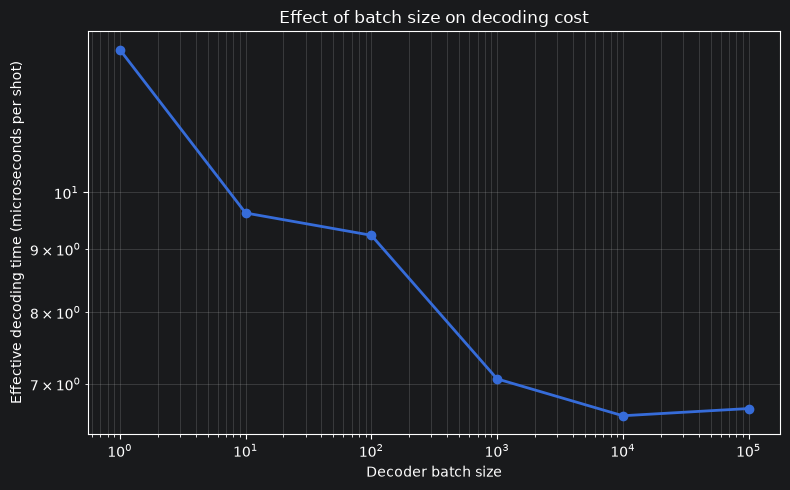

In [20]:
# Plot batching efficiency
figure, axis = plt.subplots(
    figsize=(8, 5)
)

axis.plot(
    batch_size_df[
        "batch_size"
    ],
    batch_size_df[
        "microseconds_per_shot"
    ],
    marker="o",
    linewidth=2,
)

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Decoder batch size"
)

axis.set_ylabel(
    "Effective decoding time "
    "(microseconds per shot)"
)

axis.set_title(
    "Effect of batch size on decoding cost"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

figure.tight_layout()

batch_efficiency_path = (
    FIGURE_DIR
    / "decoder_batch_size_efficiency.png"
)

figure.savefig(
    batch_efficiency_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [21]:
# Fit a log-linear explanatory model
model_df = individual_latency_df[
    individual_latency_df[
        "latency_microseconds"
    ] > 0.0
].copy()

design_matrix = np.column_stack(
    [
        np.ones(
            len(model_df)
        ),
        np.log(
            model_df[
                "distance"
            ].to_numpy()
        ),
        np.log1p(
            model_df[
                "detection_events"
            ].to_numpy()
        ),
        model_df[
            "physical_error_probability"
        ].to_numpy(),
    ]
)

target_values = np.log(
    model_df[
        "latency_microseconds"
    ].to_numpy()
)

coefficients, _, _, _ = (
    np.linalg.lstsq(
        design_matrix,
        target_values,
        rcond=None,
    )
)

coefficient_names = [
    "intercept",
    "log_distance",
    "log_one_plus_event_count",
    "physical_error_probability",
]

performance_model_df = pd.DataFrame(
    {
        "term": coefficient_names,
        "coefficient": coefficients,
    }
)

performance_model_df

,term,coefficient
0,intercept,-0.324308
1,log_distance,0.563720
2,log_one_plus_event_count,0.435542
3,physical_error_probability,50.954467


In [22]:
# Calculate predictions
predicted_log_latency = (
    design_matrix
    @ coefficients
)

predicted_latency = np.exp(
    predicted_log_latency
)

model_df[
    "predicted_latency_microseconds"
] = predicted_latency

residuals = (
    target_values
    - predicted_log_latency
)

sum_squared_residuals = np.sum(
    residuals**2
)

total_sum_squares = np.sum(
    (
        target_values
        - target_values.mean()
    ) ** 2
)

r_squared = (
    1.0
    - sum_squared_residuals
    / total_sum_squares
)

print(
    f"Log-latency model R-squared: "
    f"{r_squared:.4f}"
)

Log-latency model R-squared: 0.8527


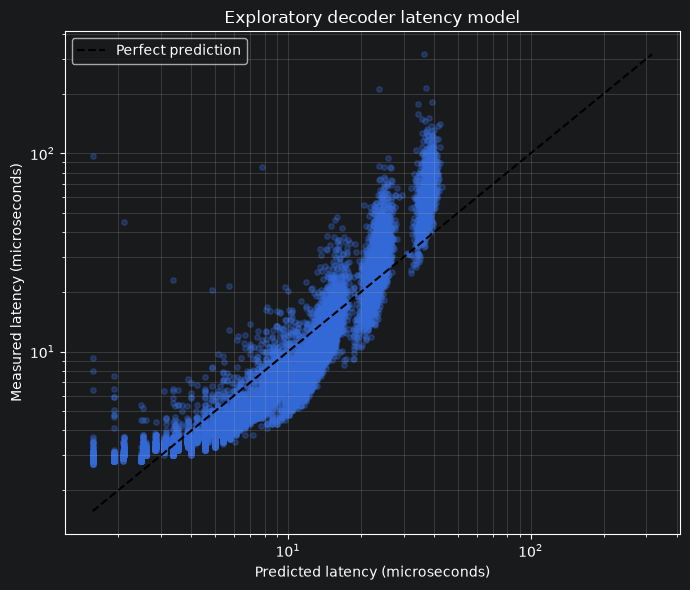

In [23]:
# Plot measured versus predicted latency
figure, axis = plt.subplots(
    figsize=(7, 6)
)

axis.scatter(
    model_df[
        "predicted_latency_microseconds"
    ],
    model_df[
        "latency_microseconds"
    ],
    s=15,
    alpha=0.3,
)

minimum_value = min(
    model_df[
        "predicted_latency_microseconds"
    ].min(),
    model_df[
        "latency_microseconds"
    ].min(),
)

maximum_value = max(
    model_df[
        "predicted_latency_microseconds"
    ].max(),
    model_df[
        "latency_microseconds"
    ].max(),
)

axis.plot(
    [
        minimum_value,
        maximum_value,
    ],
    [
        minimum_value,
        maximum_value,
    ],
    color="black",
    linestyle="--",
    label="Perfect prediction",
)

axis.set_xscale("log")
axis.set_yscale("log")

axis.set_xlabel(
    "Predicted latency "
    "(microseconds)"
)

axis.set_ylabel(
    "Measured latency "
    "(microseconds)"
)

axis.set_title(
    "Exploratory decoder latency model"
)

axis.grid(
    True,
    which="both",
    alpha=0.3,
)

axis.legend()

figure.tight_layout()

latency_model_path = (
    FIGURE_DIR
    / "decoder_latency_model.png"
)

figure.savefig(
    latency_model_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

In [24]:
# Save results
complexity_summary_path = (
    RESULTS_DIR
    / "decoder_complexity_summary.csv"
)

complexity_summary_df.to_csv(
    complexity_summary_path,
    index=False,
)

individual_latency_path = (
    RESULTS_DIR
    / "decoder_complexity_individual_latency.csv"
)

individual_latency_df.to_csv(
    individual_latency_path,
    index=False,
)

correlation_path = (
    RESULTS_DIR
    / "decoder_complexity_correlations.csv"
)

correlation_df.to_csv(
    correlation_path,
    index=False,
)

failure_complexity_path = (
    RESULTS_DIR
    / "decoder_failure_complexity.csv"
)

failure_complexity_df.to_csv(
    failure_complexity_path,
    index=False,
)

batch_size_path = (
    RESULTS_DIR
    / "decoder_batch_size_scaling.csv"
)

batch_size_df.to_csv(
    batch_size_path,
    index=False,
)

performance_model_path = (
    RESULTS_DIR
    / "decoder_latency_model_coefficients.csv"
)

performance_model_df.to_csv(
    performance_model_path,
    index=False,
)

print(
    f"Saved complexity summary to: "
    f"{complexity_summary_path}"
)

print(
    f"Saved individual latencies to: "
    f"{individual_latency_path}"
)

Saved complexity summary to: C:\Users\Karthi\Qauntum\results\decoder_complexity_summary.csv
Saved individual latencies to: C:\Users\Karthi\Qauntum\results\decoder_complexity_individual_latency.csv


# Decoder-Complexity Results

### Graph Scale and Syndrome Complexity
* **Code-Distance Scaling:** Increasing the surface-code distance $d$ expanded the number of physical qubits, detectors, and matching-graph edges. Both the larger spatial graph and longer syndrome-extraction history increased the volume of classical syndrome data presented to the decoder.
* **Event Density vs. Topology:** Higher physical error probabilities generated more detection events per shot, generally increasing decoder workload. However, detection-event count alone did not fully explain single-shot latency: the spatial and temporal arrangement of defects governs matching difficulty, alongside Python-call overhead and operating-system scheduling variability.

### Statistical Association and Failure Modes
* **Correlation Analysis:** Pearson and Spearman correlation coefficients quantified the relationship between detection-event count and decode latency—measuring linear association and monotonic scaling, respectively.
* **Statistical Failure vs. Computational Hardness:** Comparisons between successful and failed shots did not equate logical failure with high computational cost. A decoder can return an incorrect logical prediction rapidly whenever an alternative, topologically non-trivial error chain has lower matching weight under its error model. Logical failure is therefore a **statistical inference failure** rather than necessarily a **runtime bottleneck**.

### Batching, Regression, and System Constraints
* **Batch Amortisation vs. Real-Time Latency:** Batch-size scaling demonstrated substantial amortisation of Python invocation and setup overhead, yielding a much lower effective per-shot cost for large batches. While advantageous for offline Monte Carlo throughput, this gain cannot be assumed in real-time control, where buffering shots to form a batch introduces unacceptable queuing delay.
* **Interpreting Empirical Regression:** The exploratory regression model evaluated how well code distance, event count, and physical error probability accounted for empirical latency. Because sub-microsecond to microsecond host calls are heavily influenced by language bindings, memory allocation, CPU scheduling, and timer resolution, these fits represent empirical runtime behaviour rather than asymptotic algorithmic complexity.
* **Hardware Evaluation Criteria:** Specialised hardware decoders must be assessed across both algorithmic workload and system-level constraints—including detector-graph scale, event density, tail latency, sustained throughput, memory bandwidth, data-transfer overhead, and multi-patch concurrency.
